In [1]:
# Import analysis libraries.
import pandas as pd
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
import numpy as np
import scipy.stats as stats

# Import visual libraries.
import matplotlib.pyplot as plt
import matplotlib.dates as mdates
import seaborn as sns

# Import engine connection file.
from _01_database_connection import engine

The connection is successfully completed!


In [11]:
# Extract the data from the database.
fact_sales = pd.read_sql(
    sql="SELECT * FROM gold.fact_sales",
    con=engine
)

fact_sales.sample(2)

,order_number,product_key,customer_key,order_date,ship_date,due_date,price,quantity,sales
3509,SO48563,81,9832,2012-06-13,2012-06-20,2012-06-25,783,1,783
10176,SO53270,29,14530,2013-02-24,2013-03-03,2013-03-08,21,1,21


**Q1: Detect the anomalies months of revenue with the global effect of all the period ?**

In [18]:
# Ckeck data types.
fact_sales.dtypes

# Change (order_data, ship_date, due_date) columns from int into datetime.
date_columns = ["order_date", "ship_date", "due_date"]
fact_sales[date_columns] = fact_sales[date_columns].astype("datetime64[s]")

In [19]:
# Group the data by the month-year.
fact_sales["year_month"] = fact_sales["order_date"].dt.to_period("M")


# Group the data by the month-year.
monthly_grouped_revenue = (fact_sales.groupby(
                                        by="year_month"
                                        )["sales"].
                                        sum().
                                        reset_index().
                                        sort_values(by="year_month"))[:-1]

monthly_grouped_revenue

,year_month,sales
0,2011-01,469795
1,2011-02,466307
2,2011-03,485165
3,2011-04,502042
4,2011-05,561647
5,2011-06,737793
6,2011-07,596710
7,2011-08,614516
8,2011-09,603047
9,2011-10,708164


In [28]:
# Use IQR to detect the anomalies.
Q1 = monthly_grouped_revenue["sales"].quantile(q=0.25)
Q3 = monthly_grouped_revenue["sales"].quantile(q=0.75)

IQR = Q3 - Q1

lower_bound = Q1 - (IQR * 1.5)
upper_bound = Q3 + (IQR * 1.5)

anomalies_months_iqr = monthly_grouped_revenue[(monthly_grouped_revenue["sales"] < lower_bound) | (monthly_grouped_revenue["sales"] > upper_bound)]
anomalies_months_iqr

,year_month,sales
35,2013-12,1874128


In [34]:
# Use z-score to detect the anomalies.
monthly_grouped_revenue["z_score"] = stats.zscore(monthly_grouped_revenue["sales"])

anomalies_months_zscore = monthly_grouped_revenue[np.abs(monthly_grouped_revenue["z_score"]) > 3]
anomalies_months_zscore

,year_month,sales,z_score


In [35]:
# Use robust_z to detect the anomalies.
mad = stats.median_abs_deviation(monthly_grouped_revenue["sales"])
median = monthly_grouped_revenue["sales"].median()
robust_z = (0.6745 * (monthly_grouped_revenue["sales"] - median) / mad)

# Insert z-robust value in the df.
monthly_grouped_revenue["robust_z"] = robust_z

# Detect the anomalies.
anomalies_quarters_robust_z = monthly_grouped_revenue[np.abs(monthly_grouped_revenue["robust_z"]) > 3.5]
anomalies_quarters_robust_z # 2023 year hase highest growth, but it's organic growth not true anomaly.
# The anomalies months comparing the overall period.

,year_month,sales,z_score,robust_z
29,2013-06,1642948,1.87,5.21
30,2013-07,1371595,1.26,3.84
31,2013-08,1545910,1.65,4.72
32,2013-09,1447324,1.43,4.22
33,2013-10,1673261,1.93,5.36
34,2013-11,1780688,2.18,5.90
35,2013-12,1874128,2.39,6.37


**Q2: Caculate the growth of the months during the year effect not all the period?**

In [48]:
# Calculate growth  measures to produce end-to-end analysis df.

# Calculate the percentage change of each month comparing to the privouse.
monthly_grouped_revenue["pct"] = monthly_grouped_revenue["sales"].pct_change()

# Calculate the median of each month comparing to the backward 6 months and upword 6 months.
monthly_grouped_revenue["rolling_median"] = monthly_grouped_revenue["sales"].rolling(
    window=12,
    center=True,
    min_periods=6
).median()

# Calculate the mean of each month comparing to the last 6 months and upword 6 months.
monthly_grouped_revenue["rolling_mean"] = monthly_grouped_revenue["sales"].rolling(
    window=12,
    center=True,
    min_periods=6
).mean()

# # Calculate the difference between the month and the rolling median.
monthly_grouped_revenue["residual"] = (monthly_grouped_revenue["sales"] -
                                       monthly_grouped_revenue["rolling_median"])


# Calculate std of each month residual.
monthly_grouped_revenue["rolling_std_for_residual"] = monthly_grouped_revenue["residual"].rolling(
    window=12,
    center=True,
    min_periods=6
).std(ddof=1)


# Calculate z-score for the residual.
monthly_grouped_revenue["final_z"] = monthly_grouped_revenue["residual"] / monthly_grouped_revenue["rolling_std_for_residual"]

monthly_grouped_revenue

,year_month,sales,z_score,robust_z,pct,rolling_median,rolling_mean,residual,rolling_std_for_residual,final_z
0,2011-01,469795,-0.77,-0.70,NaN,"493,603.50","537,124.83","-23,808.50","74,147.76",-0.32
1,2011-02,466307,-0.78,-0.72,-0.01,"502,042.00","545,637.00","-35,735.00","67,703.20",-0.53
2,2011-03,485165,-0.74,-0.62,0.04,"531,844.50","554,246.88","-46,679.50","63,124.58",-0.74
3,2011-04,502042,-0.70,-0.54,0.03,"561,647.00","559,669.11","-59,605.00","59,093.98",-1.01
4,2011-05,561647,-0.56,-0.24,0.12,"579,178.50","574,518.60","-17,531.50","65,909.90",-0.27
5,2011-06,737793,-0.17,0.65,0.31,"596,710.00","582,335.73","141,083.00","64,504.89",2.19
6,2011-07,596710,-0.49,-0.06,-0.19,"599,878.50","589,590.67","-3,168.50","63,641.77",-0.05
7,2011-08,614516,-0.45,0.03,0.03,"599,878.50","591,721.33","14,637.50","68,888.61",0.21
8,2011-09,603047,-0.47,-0.03,-0.02,"599,878.50","595,111.75","3,168.50","68,220.22",0.05
9,2011-10,708164,-0.24,0.50,0.17,"599,878.50","585,804.50","108,285.50","80,364.42",1.35


**Q3: Draw a plot to visualize the difference between the actual sales and normal median around?**

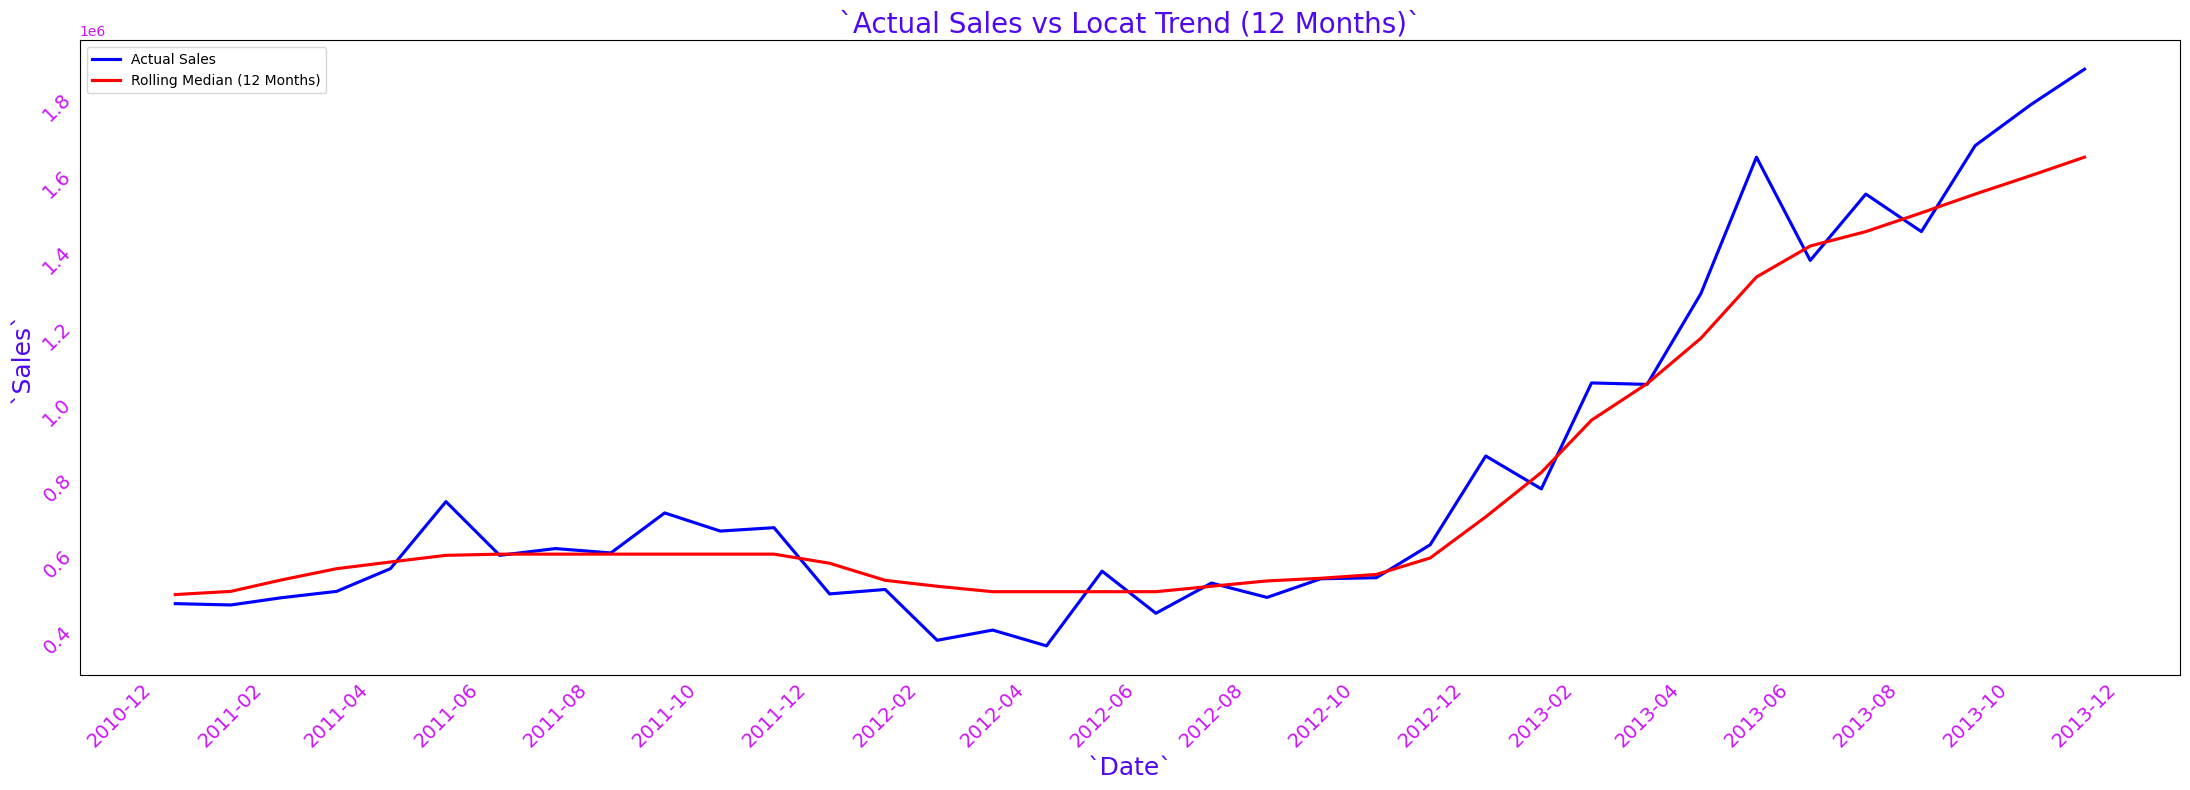

In [50]:
# Change year month column to datetime.
monthly_grouped_revenue["year_month"] = monthly_grouped_revenue["year_month"].astype("datetime64[s]")

fig, ax = plt.subplots(figsize=(22, 8))

sns.lineplot(
    data=monthly_grouped_revenue,
    x="year_month",
    y="sales",
    color="b",
    label="Actual Sales",
    linewidth=2.25,
    ax=ax
);

sns.lineplot(
    data=monthly_grouped_revenue,
    x="year_month",
    y="rolling_median",
    color="r",
    label="Rolling Median (12 Months)",
    linewidth=2.25,
    ax=ax
);


# Set labels.
ax.xaxis.set_major_locator(mdates.MonthLocator(interval=2));
ax.set_title("`Actual Sales vs Locat Trend (12 Months)`", fontsize=20, color="#4F09F1")
ax.set_ylabel("`Sales`", fontsize=18, color="#4F09F1");
ax.set_xlabel("`Date`", fontsize=18, color="#4F09F1");

ax.tick_params(rotation=45, length=0, labelcolor="#CC12FA", labelsize=14);

plt.tight_layout();